# LCD plant: discrete-event simulation (Phase 2)

An Arena-style block simulation of the NVT LCD plant built in **SimPy**. It models the Phase 1 plan:
two mixed-model cells (Fabrication WS 1-8, Assembly WS 9-12), EOQ lots, and cross-trained operator pools.

| Arena module | In this model |
|---|---|
| Create | Kits released one at a time at a constant interval, retaining the mixed-model lot sequence (M860/M970/M1080). Each product run contains `ceil(EOQ × Phase 1 scrap factor at 1-M)` component kits, e.g. 963 kits for an M860 EOQ of 754 in Year 3 |
| Separate | Follows `precedence_diagram.png`. After **1-M** the kit splits into a keyboard (→ 4-A) and an LCD/PCB set (→ 2-M). After **2-M** that splits into the power strip/PCB/LCD branch (→ 3-A → 5-A) and the backlight/sensor branch (→ 6-A). Each branch is sent `ceil(EOQ × its scrap factor)` items (the `Prod Req` sheet), so enough survive to make EOQ good units. Surplus components are counted as *spare* |
| Match / Batch | One keyboard + one power/PCB/LCD + one backlight sub-assembly **from the same lot** become one display assembly → 7-M (M860) or straight to 8-A (M970/M1080). Leftovers are counted as *unmatched* |
| Process (Seize-Delay-Release) | Machines per station + a cell operator pool. Manual benches (-M) hold the operator for the whole cycle; automatic machines (-A) only for setup / load / unload |
| Decide (2-way by chance) | Scrap draw after every operation (rate by station and model) |
| Failure (Count) | Planned maintenance every N parts; breakdowns every MTBF converted to parts. Non-preemptive: the machine finishes its part first |
| Dispose | Finished goods and the scrap log |
| DSTAT / Tally / Counter | Time-weighted queues, WIP and resource states; flow-time tallies; throughput and scrap counters |

**Rules:**
- **Times are deterministic.** Randomness comes from scrap only (failures are count-based).
- **One lot per station at a time.** A station never interleaves lots. Parts of the next lot wait at a *lot gate* until the current lot clears, which costs extra WIP but avoids extra changeovers.
- **Only productive time is simulated:** 2 shifts × 7.5 h, 5 days/week, 50 weeks/year, so 4,500 min/week.

All inputs live in `lcd_sim/params.py`. Change a scenario with `get_scenario(year, machines={...}, operators={...}, ...)`.

In [24]:
import os, warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from lcd_sim.params import get_scenario, STATIONS
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P
from lcd_sim import experiments as X

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:,.3f}".format)
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))   # parallel replications
YEAR = 3                                              # <- switch 1, 2 or 3

## 1. Scenario inputs

Setup times at stations 3-A, 4-A, 5-A, 8-A, and 11-A are reduced by 75% for all three models (25% of the original setup times).

**Experiment 1: continuous arrivals.** Release one kit every `sc.kit_interarrival_min` productive minutes (about 1.020 min in Year 3). Annual planned kit volume, product mix, EOQ run quantities, and station lot gates are retained. Products are not alternated unit by unit. Arrivals are scheduled independently of downstream completion; no WIP cap is imposed.

In [25]:
sc = get_scenario(YEAR, release_mode="continuous")          # Phase 1 plan for the year (machines, crew, EOQ, demand)
st_in, prod_in = sc.describe()
print(f"Year {sc.year}: run {sc.run_weeks} weeks after a {sc.warmup_weeks}-week warm-up | "
      f"crew per shift {sc.operators} | learning factor {sc.learning:.4f}")
display(prod_in)
display(st_in)
print(f"Arrival policy: {sc.release_mode}; one kit every {sc.kit_interarrival_min:.4f} productive min")

TypeError: Scenario.__init__() got an unexpected keyword argument 'release_mode'

## 2. One replication: how the system behaves
The time series below come from one run, including the warm-up (grey band).

Sanity checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.8861492393585957}


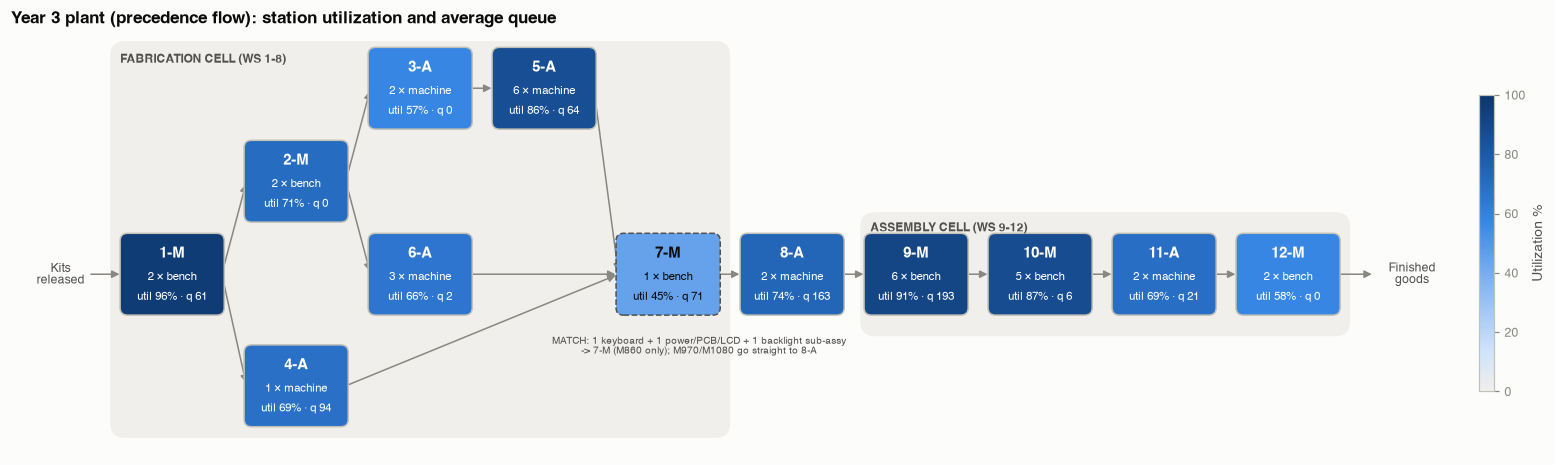

In [ ]:
res = run(sc)
print("Sanity checks:", res.checks)
P.plot_block_diagram(res); plt.show()

,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,"10,474.000","1,309.250","1,277.540",1.025,14.733,20.032
M970,"8,893.000","1,111.625","1,105.920",1.005,15.304,22.982
M1080,"9,476.000","1,184.500","1,230.320",0.963,13.710,21.153
Total,"28,843.000","3,605.375","3,613.780",0.998,14.573,22.191


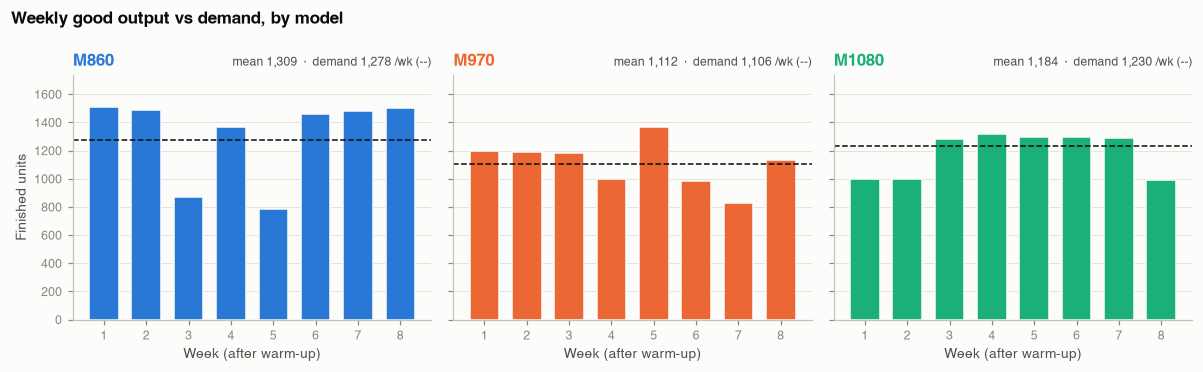

In [ ]:
display(res.throughput)
P.plot_throughput(res); plt.show()

### Wave levels: queues at each station
Each bar is one productive day (2 shifts) and shows the **average number of parts waiting** at the station, stacked by model.
- At **1-M** kits arrive individually at a constant interval. Only released kits count as WIP; unreleased kits in the product run are outside the system.
- Bars that keep growing day after day mean the station can't keep up.
- Each color is one product's lot passing through. The waves show lots arriving, waiting and clearing.

`P.plot_queue_lines(res)` shows the detailed 5-minute view, including how much of the queue is waiting behind the lot gate.

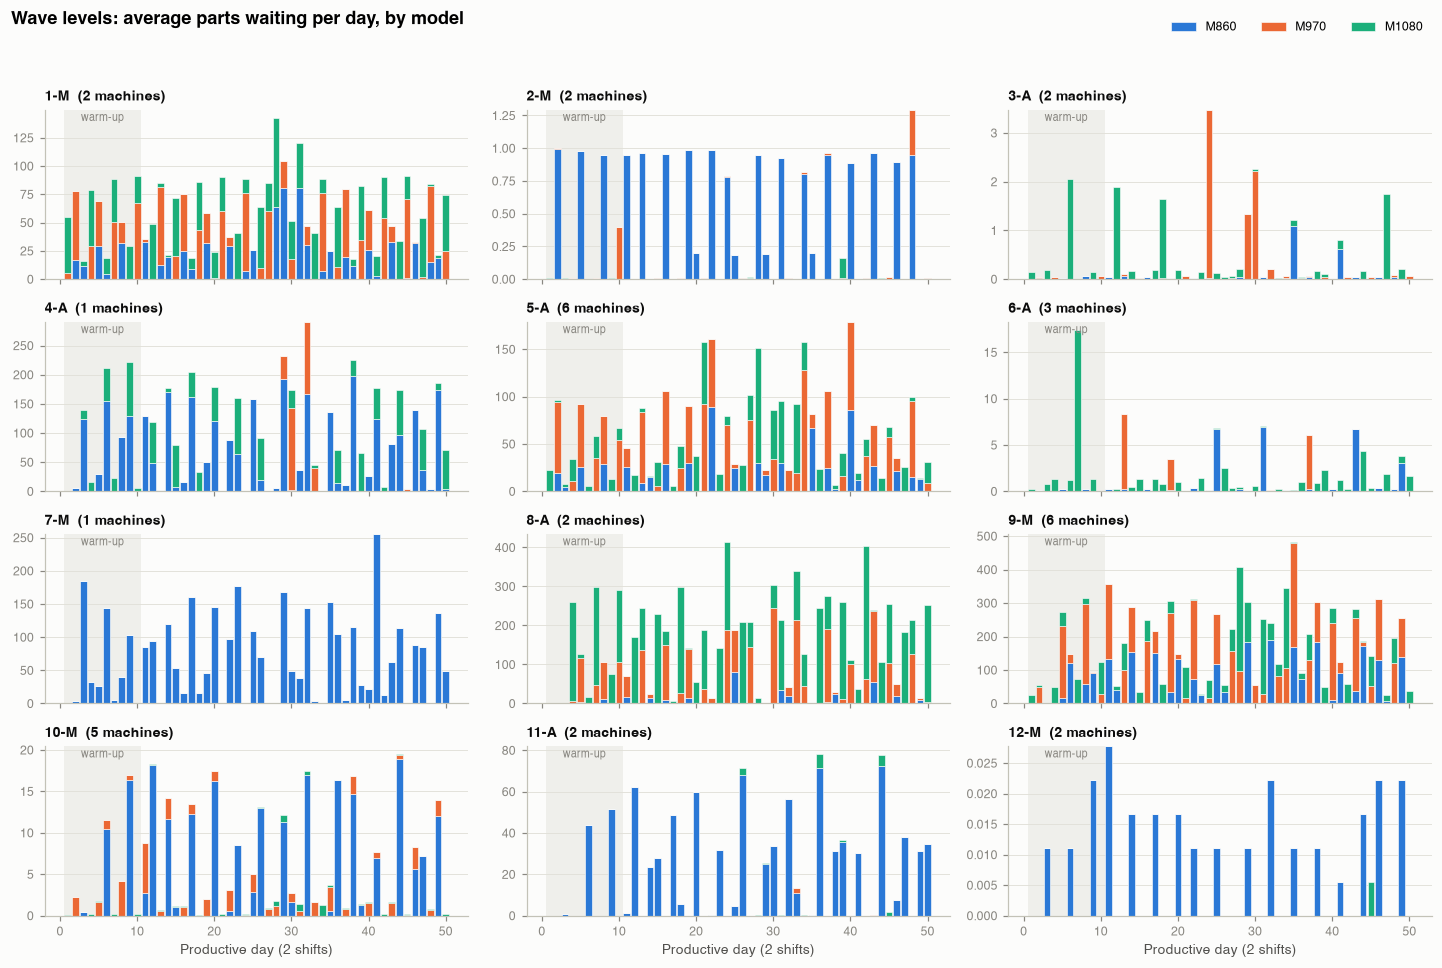

In [ ]:
P.plot_wave_levels(res); plt.show()

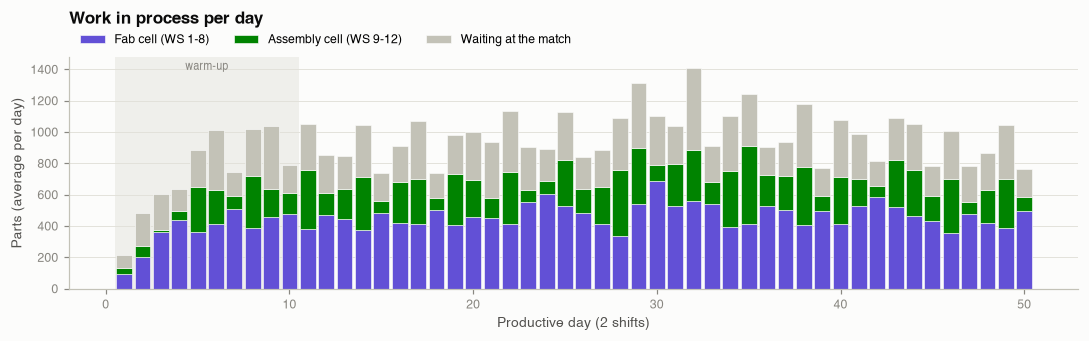

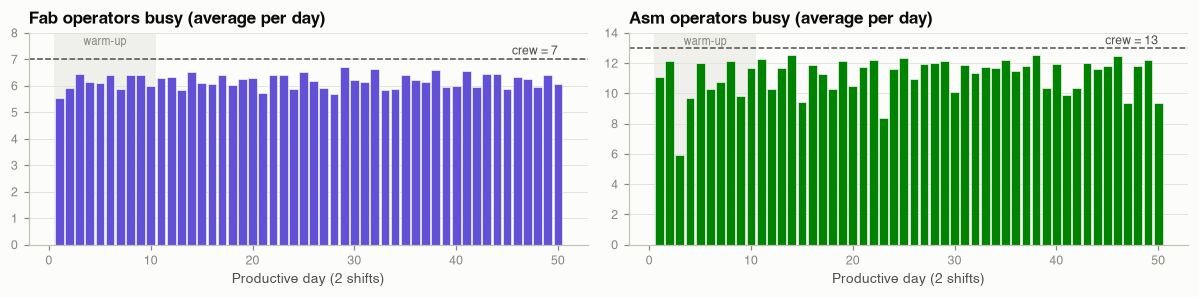

In [ ]:
P.plot_wip(res); P.plot_operators_busy(res); plt.show()

## 3. Utilization and capacity of each station and machine

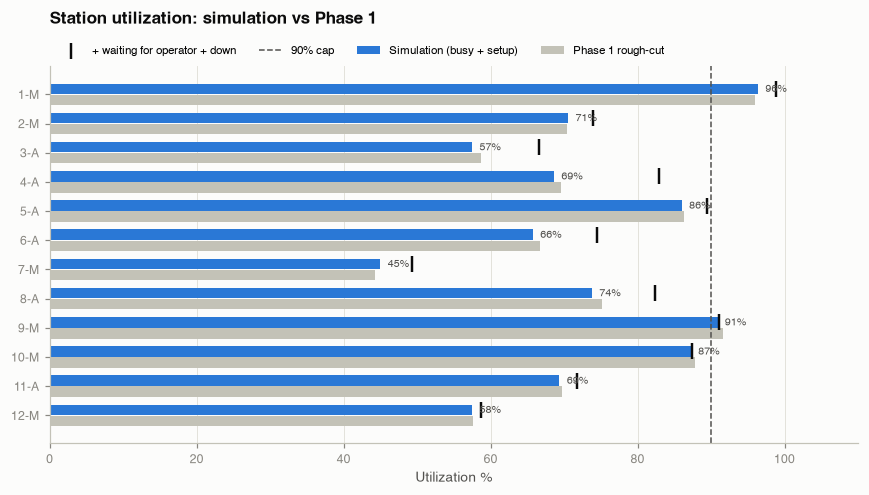

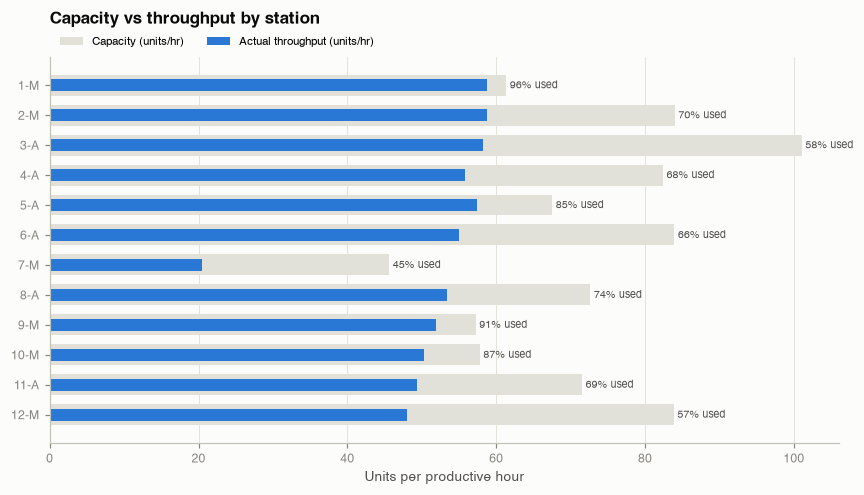

,Cell,Machines,Utilization,Busy %,Setup %,WaitOp %,Down %,Idle %,Capacity (units/hr),Throughput (units/hr),Capacity used %,Spare capacity %,Avg queue,Max queue,Avg wait (min),Wait for operator (min/part)
Station,,,,,,,,,,,,,,,,
1-M,Fab,2,0.964,0.958,0.006,0.024,0.000,0.012,61.332,58.770,0.958,0.042,60.777,184.000,62.049,0.049
2-M,Fab,2,0.706,0.697,0.008,0.033,0.001,0.260,83.978,58.770,0.700,0.300,0.359,24.000,0.366,0.067
3-A,Fab,2,0.575,0.572,0.003,0.085,0.006,0.334,101.043,58.288,0.577,0.423,0.427,32.000,0.439,0.175
4-A,Fab,1,0.686,0.683,0.003,0.133,0.010,0.171,82.383,55.850,0.678,0.322,93.979,381.000,100.962,0.142
5-A,Fab,6,0.860,0.846,0.015,0.028,0.007,0.105,67.506,57.452,0.851,0.149,63.903,291.000,66.738,0.175
6-A,Fab,3,0.658,0.653,0.004,0.075,0.012,0.255,83.916,55.062,0.656,0.344,1.729,68.000,1.884,0.246
7-M,Fab,1,0.450,0.450,0.000,0.042,0.001,0.507,45.605,20.523,0.450,0.550,70.517,316.000,206.157,0.123
8-A,Fab,2,0.738,0.734,0.004,0.080,0.006,0.176,72.631,53.398,0.735,0.265,162.677,485.000,182.788,0.181
9-M,Asm,6,0.909,0.907,0.002,0.001,0.000,0.090,57.228,51.945,0.908,0.092,192.920,553.000,222.835,0.010


In [ ]:
P.plot_utilization(res); P.plot_capacity(res); plt.show()
display(res.stations[["Cell", "Machines", "Utilization", "Busy %", "Setup %", "WaitOp %", "Down %", "Idle %",
                      "Capacity (units/hr)", "Throughput (units/hr)", "Capacity used %", "Spare capacity %",
                      "Avg queue", "Max queue", "Avg wait (min)", "Wait for operator (min/part)"]])

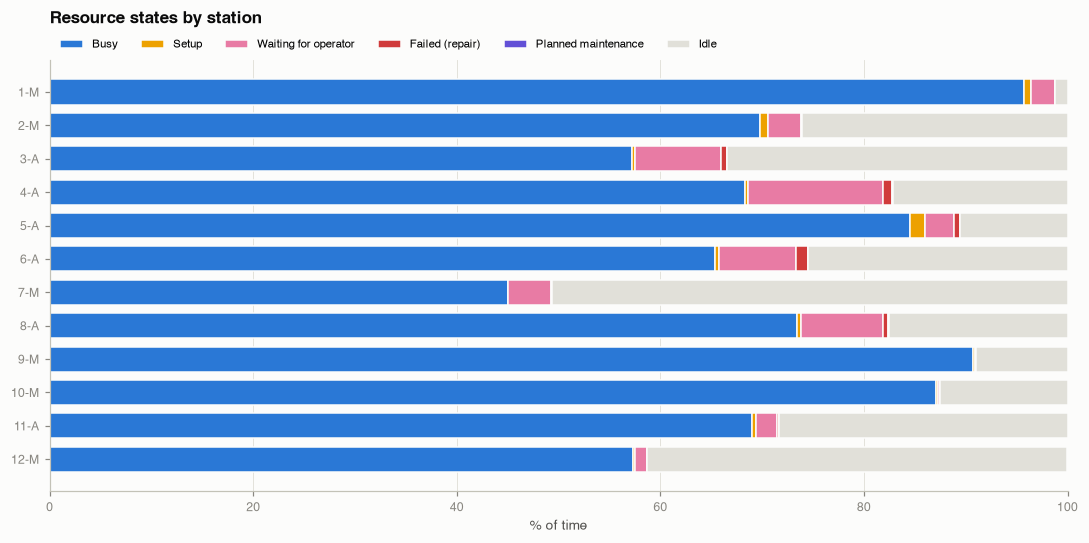

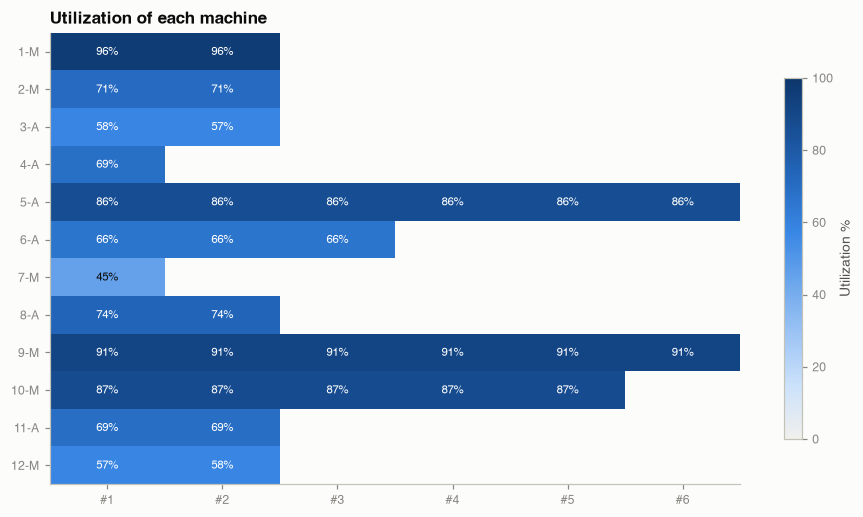

In [ ]:
P.plot_machine_states(res, by='station'); P.plot_machine_heatmap(res); plt.show()

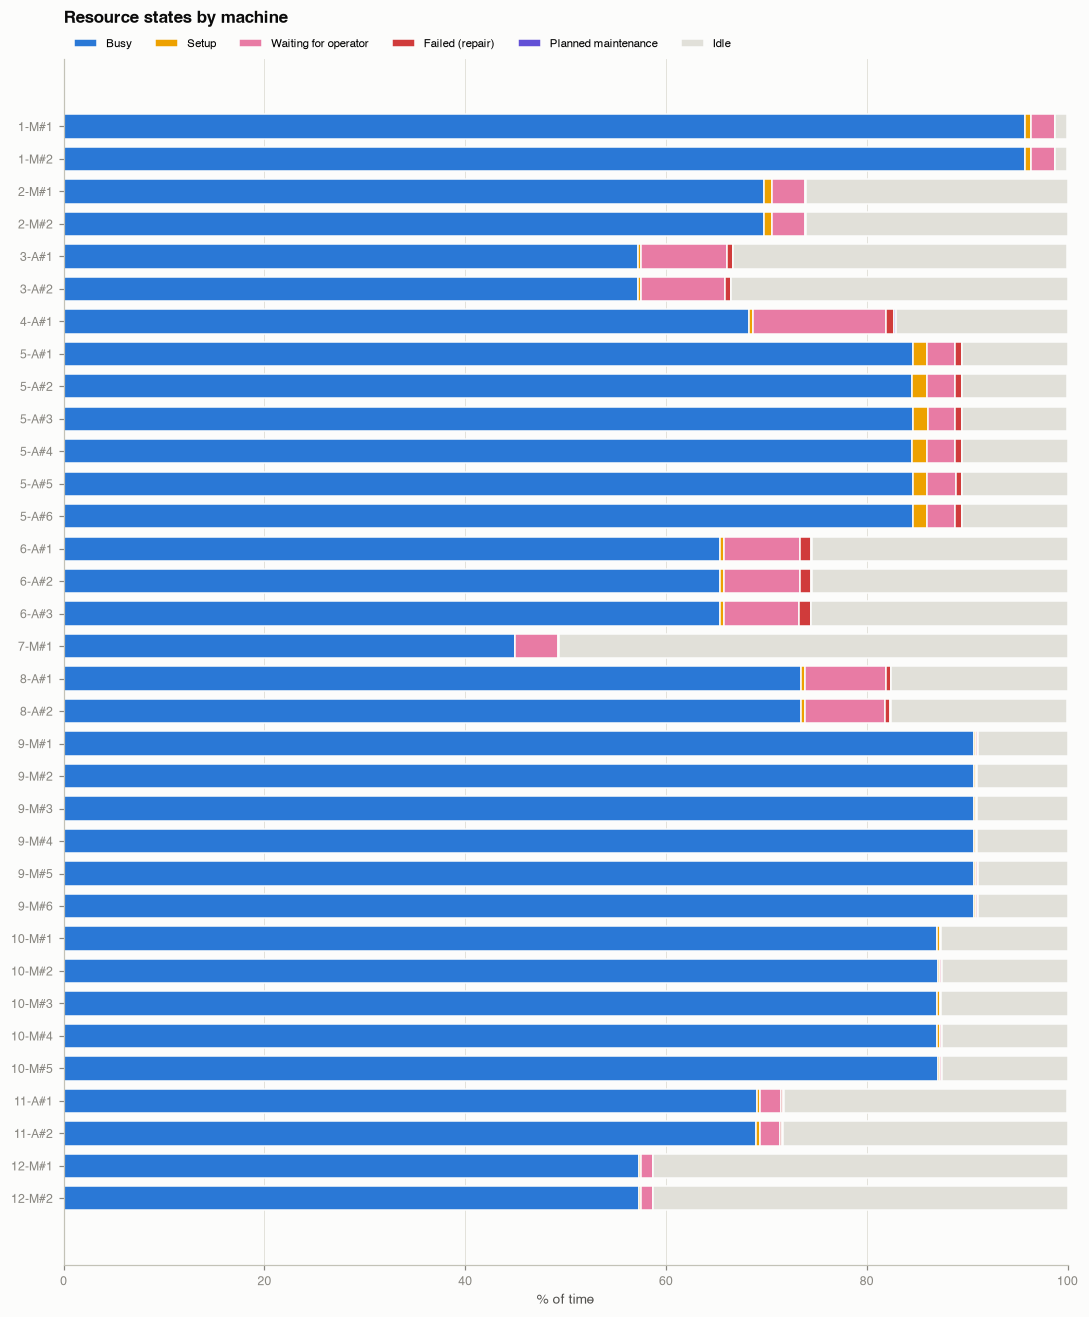

,Station,Busy %,Setup %,WaitOp %,Idle %,Failed %,PM %,Utilization,Units,Setups,Failures,PMs
Machine,,,,,,,,,,,,
1-M#1,1-M,0.958,0.006,0.024,0.012,0.000,0.000,0.964,17631,14,0,0
1-M#2,1-M,0.958,0.006,0.024,0.012,0.000,0.000,0.964,17631,14,0,0
2-M#1,2-M,0.698,0.008,0.033,0.261,0.001,0.000,0.706,17633,14,4,0
2-M#2,2-M,0.697,0.008,0.033,0.260,0.001,0.000,0.706,17629,14,4,0
3-A#1,3-A,0.572,0.003,0.086,0.333,0.006,0.000,0.575,17492,44,7,1
3-A#2,3-A,0.572,0.003,0.084,0.335,0.006,0.000,0.575,17481,44,7,1
4-A#1,4-A,0.683,0.003,0.133,0.171,0.008,0.002,0.686,33510,44,5,3
5-A#1,5-A,0.846,0.015,0.028,0.105,0.007,0.000,0.860,5745,44,2,0
5-A#2,5-A,0.845,0.015,0.028,0.106,0.007,0.000,0.860,5744,44,2,0


In [ ]:
P.plot_machine_states(res, by='machine'); plt.show()
display(res.machines)

## 4. Operators: who works where and for how long
Operators are cross-trained within their cell, so any free cell operator takes the next task.
*Waiting for operator* on a machine means the machine was ready but no operator was free.

,Crew per shift,Avg busy,Peak busy,Utilization,Avg WIP in cell,Avg wait for operator (min/part),Avg wait for machine (min/part)
Cell,,,,,,,
Fab,7,6.195,7.000,0.885,469.616,0.145,65.203
Asm,13,11.329,13.000,0.871,232.451,0.025,66.123


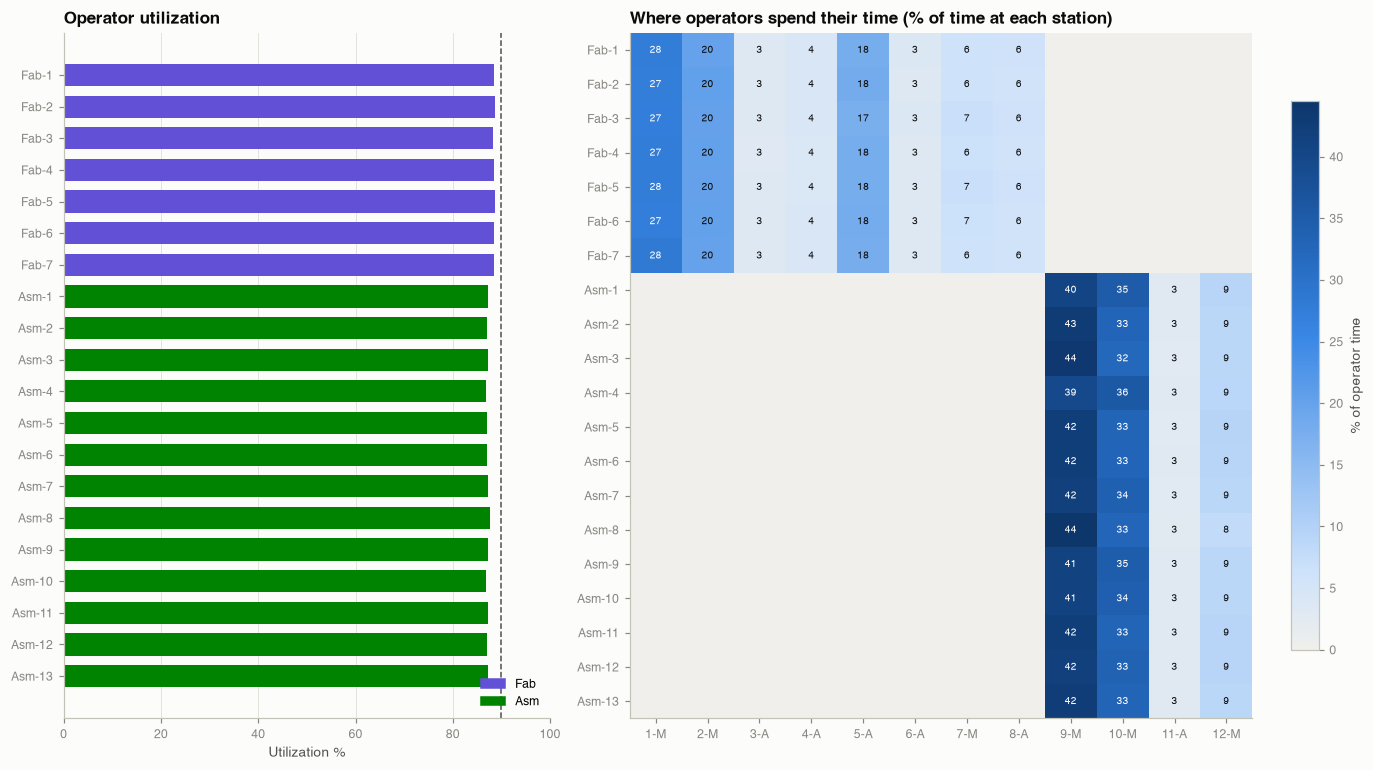

,Cell,Busy (hr),Utilization,Main station,1-M hr,2-M hr,3-A hr,4-A hr,5-A hr,6-A hr,7-M hr,8-A hr,9-M hr,10-M hr,11-A hr,12-M hr
Fab-1,Fab,530.959,0.885,1-M,165.700,119.500,19.000,25.300,107.200,20.900,37.200,36.100,0.000,0.000,0.000,0.000
Fab-2,Fab,531.480,0.886,1-M,164.300,122.800,18.800,24.300,109.400,20.300,36.700,34.900,0.000,0.000,0.000,0.000
Fab-3,Fab,529.843,0.883,1-M,163.600,120.400,19.400,25.100,104.000,20.900,40.400,36.000,0.000,0.000,0.000,0.000
Fab-4,Fab,531.370,0.886,1-M,165.000,121.800,18.800,24.000,107.300,20.600,38.700,35.200,0.000,0.000,0.000,0.000
Fab-5,Fab,531.690,0.886,1-M,165.000,120.800,18.800,23.800,107.100,19.400,40.800,35.900,0.000,0.000,0.000,0.000
Fab-6,Fab,531.076,0.885,1-M,163.400,121.800,19.000,24.500,108.100,20.100,39.400,34.600,0.000,0.000,0.000,0.000
Fab-7,Fab,530.813,0.885,1-M,169.800,119.600,19.000,24.600,105.800,20.200,36.800,35.100,0.000,0.000,0.000,0.000
Asm-1,Asm,523.033,0.872,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,242.700,209.000,17.000,54.300
Asm-2,Asm,522.298,0.870,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,255.900,196.700,17.300,52.400
Asm-3,Asm,523.214,0.872,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,262.200,192.400,16.500,52.200


In [ ]:
display(res.cells)
P.plot_operators(res); plt.show()
display(res.operators.join((res.op_station / 60).round(1).add_suffix(" hr")))

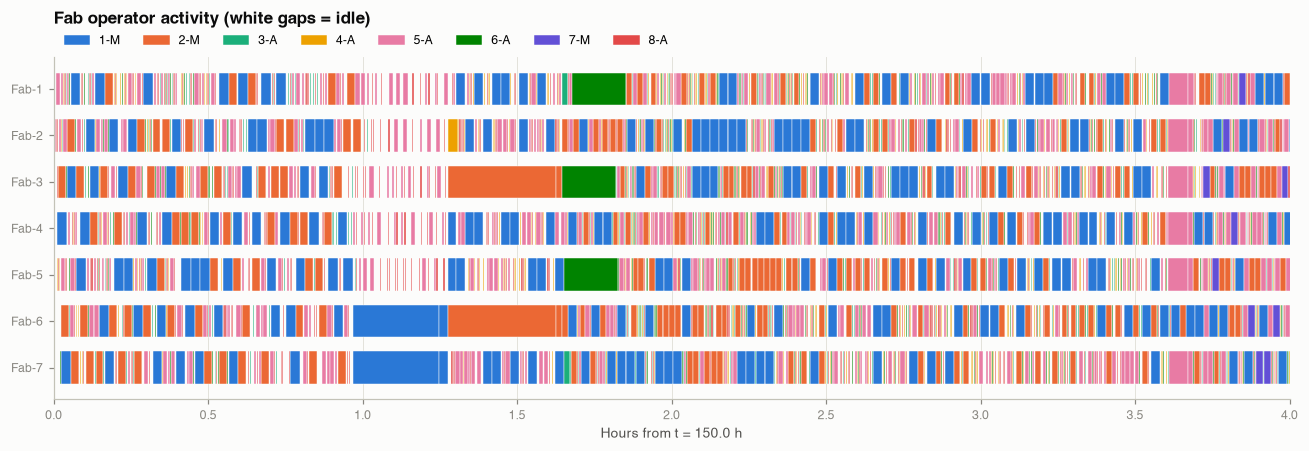

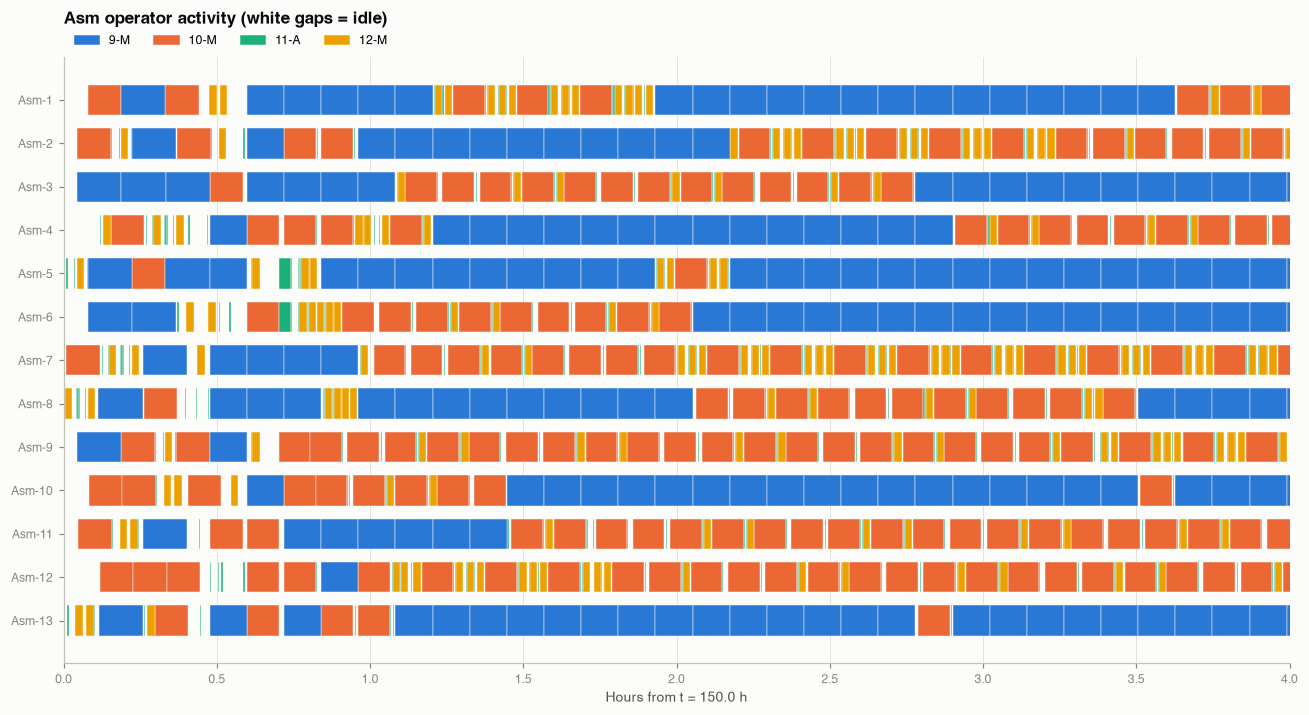

,Operator,Cell,Station,Machine,Task,Lot,Model,Start,End
0,Fab-3,Fab,4-A,4-A#1,unload,11,M970,"9,000.101","9,000.199"
1,Asm-8,Asm,11-A,11-A#2,unload,10,M1080,"9,000.157","9,000.357"
2,Fab-2,Fab,5-A,5-A#1,unload,11,M970,"9,000.128","9,000.532"
3,Fab-1,Fab,3-A,3-A#2,load,11,M970,"9,000.478","9,000.573"
4,Fab-3,Fab,6-A,6-A#3,load,11,M970,"9,000.478","9,000.583"


In [ ]:
P.plot_operator_gantt(res, cell="Fab", hours=4); P.plot_operator_gantt(res, cell="Asm", hours=4); plt.show()
res.op_log.head()   # one row per operator task: who, which station/machine, what, when

## 5. Scrap, spare parts and lot completion
Scrap is logged per item: kit, sub-assembly or finished assembly. A scrapped keyboard loses only the keyboard, not the whole unit.

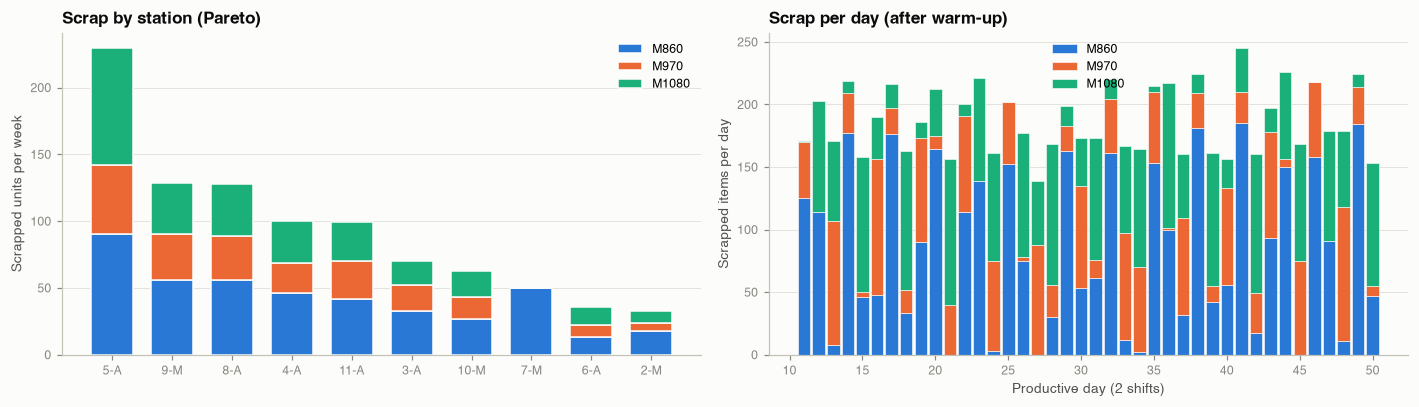

Units per week  Invested_min per week  Labor_dollars per week
Station Item                         Model                                                               
10-M    Display assembly             M1080          19.100                771.400                 153.000
                                     M860           26.800                592.900                 136.100
                                     M970           16.600                565.200                 115.600
11-A    Display assembly             M1080          29.000              1,221.200                 235.200
                                     M860           41.900                998.200                 215.100
                                     M970           28.500              1,013.800                 202.600
2-M     LCD/PCB set                  M1080           8.600                 34.000                   8.700
                                     M860           17.900                 51.400                  13.200
                                     M970            6.100                 20.800                   5.400
3-A     Power strip/PCB/LCD sub-assy M1080          17.500                 98.400                  19.200
                                     M860           33.000                113.600                  26.200
                                     M970           19.200                 92.500                  18.000
4-A     Keyboard sub-assy            M1080          31.800                 94.200                  21.000
                                     M860           46.100                125.000                  25.500
                                     M970           22.200                 52.000                  11.800
5-A     Power strip/PCB/LCD sub-assy M1080          87.600              1,128.100                 132.600
                                     M860           90.400                554.700                 106.400
                                     M970           51.500                580.000                  70.300
6-A     Backlight/sensor sub-assy    M1080          13.200                 96.000                  14.500
                                     M860           13.400                 55.100                  10.600
                                     M970            9.000                 48.300                   8.400
7-M     Display assembly             M860           49.900                712.400                 143.300
8-A     Display assembly             M1080          39.000                981.200                 134.500
                                     M860           55.900                873.500                 168.100
                                     M970           33.200                682.200                  96.200
9-M     Display assembly             M1080          38.200              1,292.900                 229.900
                                     M860           55.600              1,057.200                 223.500
                                     M970           35.000                972.600                 177.000

,EOQ,Kits,Finished,Finished / EOQ,Short of EOQ,Scrapped,Spare,Unmatched,Yield (finished / kits),Planned yield,Lot flow time (hr)
Model,,,,,,,,,,,
M1080,655.000,785.000,649.222,0.991,6.889,155.611,92.889,13.611,0.827,0.835,26.094
M860,754.000,963.000,749.235,0.994,6.176,245.412,104.529,19.765,0.778,0.783,25.980
M970,596.000,699.000,591.833,0.993,5.944,123.278,58.778,12.333,0.847,0.853,25.088


Spare = components not needed at a Separate; Unmatched = sub-assemblies left at the Match when the lot closed.


In [ ]:
P.plot_scrap(res); plt.show()
weeks = res.T / 4500
scr = res.scrap.groupby(["Station", "Item", "Model"]).agg(Units=("Part", "count"), Invested_min=("Invested min", "sum"),
                                                   Labor_dollars=("Labor $", "sum"))
display((scr / weeks).round(1).rename(columns=lambda c: c + " per week"))
lots = res.lots.dropna(subset=["Done"])
display(lots.groupby("Model")[["EOQ", "Kits", "Finished", "Finished / EOQ", "Short of EOQ", "Scrapped", "Spare",
                               "Unmatched", "Yield (finished / kits)", "Planned yield", "Lot flow time (hr)"]].mean())
print("Spare = components not needed at a Separate; Unmatched = sub-assemblies left at the Match when the lot closed.")

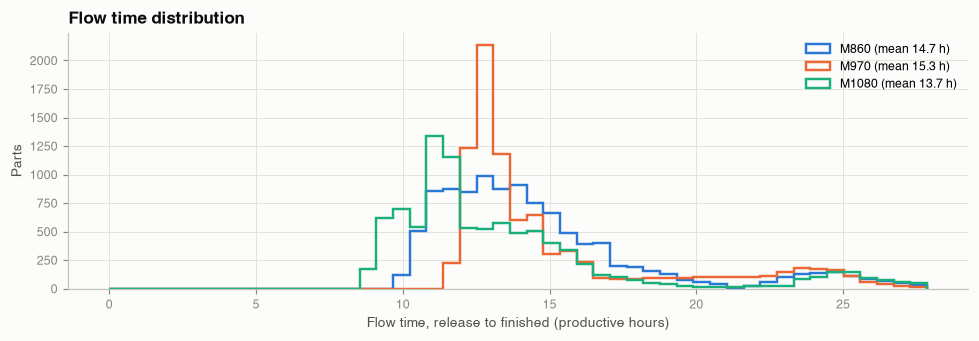

In [ ]:
P.plot_flow_time(res); plt.show()

## 6. Replications (Arena Category Overview)
Each replication uses a new random seed for scrap. The table shows the average, the 95% half-width, and the min and max across replications.

In [ ]:
reps, summary = run_replications(sc, n=10, n_jobs=N_JOBS)
summary

Average  Half Width   Minimum   Maximum
Category            Statistic                                                                    
Throughput          M860 per week                       1,312.088       4.742 1,303.625 1,321.875
                    M970 per week                       1,110.263       2.998 1,102.375 1,115.250
                    M1080 per week                      1,186.463       2.461 1,182.250 1,191.750
                    Total per week                      3,608.812       6.809 3,590.250 3,623.000
                    % of demand                             0.999       0.002     0.993     1.003
Flow time (hr)      M860                                   14.828       0.078    14.648    15.000
                    M970                                   15.406       0.067    15.279    15.579
                    M1080                                  13.784       0.067    13.601    13.927
WIP                 Average WIP (parts)                   984.301       3.900   975.806   993.479
                    Ending WIP (parts)                    772.100      10.553   746.000   789.000
Operators           Fab utilization                         0.885       0.000     0.885     0.886
                    Fab wait for operator (min/part)        0.146       0.001     0.145     0.148
                    Asm utilization                         0.872       0.001     0.870     0.874
                    Asm wait for operator (min/part)        0.025       0.001     0.024     0.027
Station utilization 1-M                                     0.964       0.000     0.964     0.964
                    2-M                                     0.706       0.000     0.706     0.706
                    3-A                                     0.575       0.000     0.575     0.575
                    4-A                                     0.686       0.000     0.686     0.686
                    5-A                                     0.860       0.000     0.859     0.861
                    6-A                                     0.658       0.000     0.657     0.658
                    7-M                                     0.451       0.000     0.450     0.452
                    8-A                                     0.739       0.001     0.737     0.741
                    9-M                                     0.909       0.001     0.907     0.911
                    10-M                                    0.873       0.001     0.871     0.876
                    11-A                                    0.694       0.001     0.691     0.696
                    12-M                                    0.576       0.001     0.573     0.578
Avg queue           1-M                                    60.493       0.204    60.063    60.920
                    2-M                                     0.360       0.002     0.355     0.362
                    3-A                                     0.453       0.009     0.427     0.467
                    4-A                                    93.416       0.428    92.657    94.456
                    5-A                                    64.636       0.782    62.789    66.442
                    6-A                                     1.699       0.054     1.527     1.778
                    7-M                                    71.545       0.621    70.517    73.024
                    8-A                                   165.961       1.832   162.677   171.315
                    9-M                                   192.289       0.983   190.735   194.602
                    10-M                                    5.990       0.132     5.693     6.189
                    11-A                                   20.985       0.378    20.184    21.780
                    12-M                                    0.006       0.000     0.005     0.006
Down %              1-M                                     0.000       0.000     0.000     0.000
                    2-M                 

## 7. Bottlenecks: are they where Phase 1 expected?
Phase 1 (Table 2.3.1) ranked stations by rough-cut utilization and flagged **9-M and 10-M** as the bottlenecks.
The simulation adds what the spreadsheet can't capture:
- queueing,
- time machines lose waiting for a shared operator,
- setups at every lot changeover,
- the lot gate,
- failures and PM.

In [ ]:
bn = res.bottlenecks()
display(bn)
avg_util = summary.xs("Station utilization").Average.rename("Avg util (10 reps)")
avg_q = summary.xs("Avg queue").Average.rename("Avg queue (10 reps)")
display(pd.concat([avg_util, avg_q], axis=1).join(bn[["Phase 1 util"]]).sort_values("Avg util (10 reps)", ascending=False))

,Machines,Utilization,Phase 1 util,Avg queue,Avg wait (min),Gate-blocked %,Wait for operator (min/part),Down %,Spare capacity %,Sim rank,Phase 1 rank
Station,,,,,,,,,,,
1-M,2,0.964,0.960,60.777,62.049,0.001,0.049,0.000,0.042,1,1
9-M,6,0.909,0.916,192.920,222.835,0.005,0.010,0.000,0.092,2,2
10-M,5,0.873,0.878,6.189,7.393,0.001,0.012,0.000,0.131,3,3
5-A,6,0.860,0.864,63.903,66.738,0.005,0.175,0.007,0.149,4,4
8-A,2,0.738,0.751,162.677,182.788,0.102,0.181,0.006,0.265,5,5
2-M,2,0.706,0.704,0.359,0.366,0.000,0.067,0.001,0.300,6,6
11-A,2,0.694,0.697,20.899,25.386,0.000,0.050,0.003,0.309,7,7
4-A,1,0.686,0.695,93.979,100.962,0.000,0.142,0.010,0.322,8,8
6-A,3,0.658,0.667,1.729,1.884,0.000,0.246,0.012,0.344,9,9


,Avg util (10 reps),Avg queue (10 reps),Phase 1 util
Statistic,,,
1-M,0.964,60.493,0.960
9-M,0.909,192.289,0.916
10-M,0.873,5.990,0.878
5-A,0.860,64.636,0.864
8-A,0.739,165.961,0.751
2-M,0.706,0.360,0.704
11-A,0.694,20.985,0.697
4-A,0.686,93.416,0.695
6-A,0.658,1.699,0.667


## 8. Validation against Phase 1
- **(a)** With failures and PM off and Phase 1's convention of one setup per lot per station (`setup_scope="station"`), station utilization should reproduce the Phase 1 table. Check it in Year 3, where the plan has capacity to spare.
- **(b)** Each lot should deliver about EOQ good units (sending EOQ × scrap factor through each branch).
- **(c)** Accounting checks must hold.

The Phase 1 capacity check below explicitly uses historical whole-lot arrivals. The main run and operational studies use continuous arrivals. Flow time for a finished assembly is measured from its oldest constituent kit arrival; lot flow time starts at the first kit of the run.

In [ ]:
v = run(get_scenario(3, release_mode="batch", failures_on=False, pm_on=False, setup_scope="station", run_weeks=20, keep_logs=False))
cmp = pd.DataFrame({"Sim util + down": v.stations.Utilization + v.stations["Down %"], "Phase 1": v.stations["Phase 1 util"]})
cmp["Diff (pts)"] = (cmp.iloc[:, 0] - cmp.iloc[:, 1]) * 100
display(cmp)
assert cmp["Diff (pts)"].abs().max() < 5, "Year 3 utilization differs from Phase 1 by > 5 pts"
assert v.throughput.loc["Total", "% of demand"] > 0.97
assert all(val == 0 for key, val in v.checks.items() if "must be 0" in key), v.checks
ly = res.lots.dropna(subset=["Done"]).groupby("Model")[["EOQ", "Finished", "Finished / EOQ", "Yield (finished / kits)", "Planned yield"]].mean()
display(ly)
assert (ly["Finished / EOQ"] - 1).abs().max() < 0.03
print("Validation passed")

,Sim util + down,Phase 1,Diff (pts)
Station,,,
1-M,0.961,0.960,0.179
2-M,0.703,0.704,-0.041
3-A,0.576,0.587,-1.078
4-A,0.682,0.695,-1.290
5-A,0.852,0.864,-1.178
6-A,0.655,0.667,-1.178
7-M,0.443,0.442,0.080
8-A,0.741,0.751,-0.988
9-M,0.912,0.916,-0.435


,EOQ,Finished,Finished / EOQ,Yield (finished / kits),Planned yield
Model,,,,,
M1080,655.000,649.222,0.991,0.827,0.835
M860,754.000,749.235,0.994,0.778,0.783
M970,596.000,591.833,0.993,0.847,0.853


Validation passed


## 9. Setup policy: every machine vs one setup per lot
In the base model **every machine** at a station pays the setup when it starts a lot of a different model. At 5-A for M1080 that is up to 6 × (16.25 / 0.99) min after the setup reduction, and each setup also ties up a Fab operator.
Phase 1 costed **one setup per lot per station**. This compares the two, plus giving 1-M (the busiest manual bench) first call on Fab operators.

Scenario,Every machine sets up (base),One setup per lot (Phase 1),Base + 1-M operator priority
KPI,,,
Throughput|Total per week,3.6e+03 ± 10,3.61e+03 ± 12,3.61e+03 ± 9.7
Throughput|% of demand,0.997 ± 0.0029,0.998 ± 0.0032,0.998 ± 0.0027
WIP|Average WIP (parts),985 ± 6.4,804 ± 6.8,986 ± 11
WIP|Ending WIP (parts),779 ± 5.3,694 ± 19,800 ± 25
Flow time (hr)|M860,14.8 ± 0.13,12.8 ± 0.1,15.1 ± 0.18
Flow time (hr)|M970,15.4 ± 0.11,13.6 ± 0.13,15.5 ± 0.14
Flow time (hr)|M1080,13.8 ± 0.096,11.4 ± 0.091,13.6 ± 0.12
Operators|Fab utilization,0.885 ± 0.00022,0.871 ± 0.00025,0.885 ± 0.00033
Operators|Asm utilization,0.871 ± 0.0013,0.87 ± 0.0013,0.871 ± 0.002


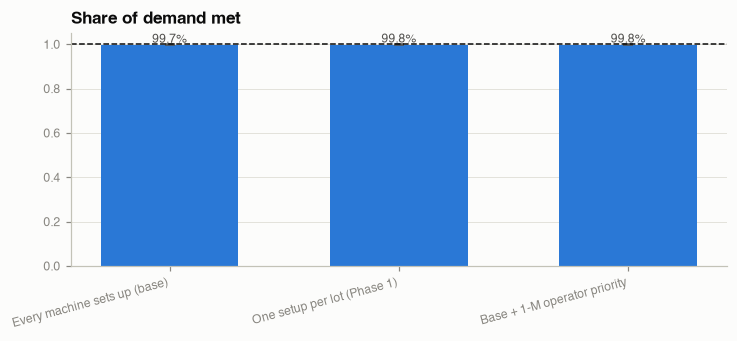

In [ ]:
long_s, wide_s = X.compare({
    "Every machine sets up (base)": get_scenario(YEAR),
    "One setup per lot (Phase 1)": get_scenario(YEAR, setup_scope="station"),
    "Base + 1-M operator priority": get_scenario(YEAR, op_priority={"1-M": -1}),
}, n=5, n_jobs=N_JOBS)
display(wide_s.loc[X.KEY_KPIS])
P.plot_compare(long_s, "Throughput|% of demand", "Share of demand met", fmt="{:.1%}", ref=1.0); plt.show()

## 10. Maintenance and failures
- PM is every N units (PM frequency).
- Breakdowns are every MTBF × 60 / (average minutes per part) units.
- TQM cuts downtime by 75%.

Scenario,No failures / PM,PM only,Failures + PM (base),TQM (-75% downtime)
KPI,,,,
Throughput|Total per week,3.6e+03 ± 11,3.61e+03 ± 9.7,3.6e+03 ± 10,3.6e+03 ± 6.8
Throughput|% of demand,0.997 ± 0.0029,0.999 ± 0.0027,0.997 ± 0.0029,0.997 ± 0.0019
WIP|Average WIP (parts),951 ± 8.7,949 ± 9.3,985 ± 6.4,956 ± 7.2
WIP|Ending WIP (parts),760 ± 13,757 ± 12,779 ± 5.3,754 ± 21
Flow time (hr)|M860,14.4 ± 0.17,14.3 ± 0.14,14.8 ± 0.13,14.4 ± 0.07
Flow time (hr)|M970,15 ± 0.12,15 ± 0.11,15.4 ± 0.11,15.1 ± 0.058
Flow time (hr)|M1080,13.4 ± 0.11,13.4 ± 0.12,13.8 ± 0.096,13.5 ± 0.13
Operators|Fab utilization,0.885 ± 0.00044,0.885 ± 0.00036,0.885 ± 0.00022,0.885 ± 0.00027
Operators|Asm utilization,0.871 ± 0.0025,0.872 ± 0.0012,0.871 ± 0.0013,0.871 ± 0.0016


Scenario,No failures / PM,PM only,Failures + PM (base),TQM (-75% downtime)
KPI,,,,
Down %|1-M,0 ± 0,0 ± 0,0 ± 0,0 ± 0
Down %|2-M,0 ± 0,0 ± 0,0.00111 ± 0,0.000278 ± 0
Down %|3-A,0 ± 0,0.000278 ± 0,0.00611 ± 0,0.00153 ± 0
Down %|4-A,0 ± 0,0.00167 ± 3e-19,0.01 ± 0,0.0025 ± 0
Down %|5-A,0 ± 0,0 ± 0,0.00667 ± 1.2e-18,0.00167 ± 3e-19
Down %|6-A,0 ± 0,0.000556 ± 0,0.0122 ± 0,0.00306 ± 0
Down %|7-M,0 ± 0,0 ± 0,0.00125 ± 0,0.000313 ± 0
Down %|8-A,0 ± 0,0.000833 ± 1.5e-19,0.00583 ± 0,0.00146 ± 0
Down %|9-M,0 ± 0,0 ± 0,0 ± 0,0 ± 0


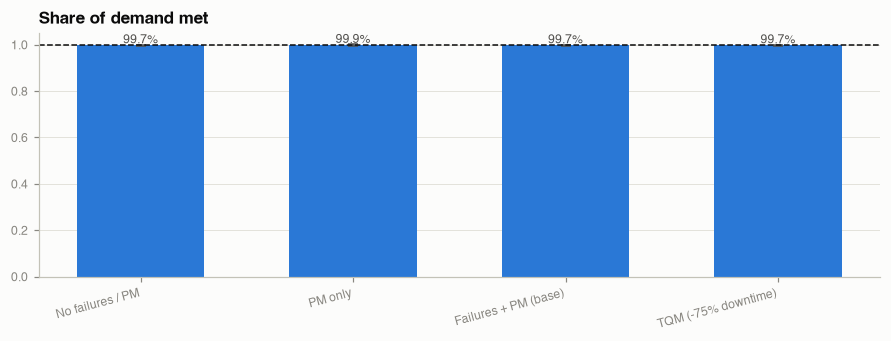

In [ ]:
long_m, wide_m = X.maintenance_study(YEAR, n=5, n_jobs=N_JOBS)
display(wide_m.loc[X.KEY_KPIS])
display(wide_m.loc[[k for k in wide_m.index if k.startswith("Down %")]])
P.plot_compare(long_m, "Throughput|% of demand", "Share of demand met", fmt="{:.1%}", ref=1.0); plt.show()

## 11. Do we need more operators?
The sweep adds or removes operators per shift in each cell, keeping the other cell at plan.
Watch throughput, WIP, and *wait for operator*.

Scenario,Fab 6 (-1),Fab 7 (+0),Fab 8 (+1),Fab 9 (+2)
KPI,,,,
Throughput|Total per week,3.25e+03 ± 6.8,3.6e+03 ± 10,3.61e+03 ± 7.6,3.61e+03 ± 6.8
Throughput|% of demand,0.899 ± 0.0019,0.997 ± 0.0029,0.999 ± 0.0021,0.998 ± 0.0019
WIP|Average WIP (parts),7.31e+03 ± 76,985 ± 6.4,779 ± 6.9,746 ± 6.5
WIP|Ending WIP (parts),1e+04 ± 1.4e+02,779 ± 5.3,705 ± 6.9,696 ± 15
Flow time (hr)|M860,61.2 ± 0.49,14.8 ± 0.13,12.6 ± 0.094,11.9 ± 0.11
Flow time (hr)|M970,61.9 ± 0.44,15.4 ± 0.11,13.4 ± 0.12,13.1 ± 0.087
Flow time (hr)|M1080,61.6 ± 0.47,13.8 ± 0.096,11.3 ± 0.099,10.9 ± 0.1
Operators|Fab utilization,0.981 ± 0.00024,0.885 ± 0.00022,0.775 ± 0.00013,0.689 ± 0.00022
Operators|Asm utilization,0.794 ± 0.0019,0.871 ± 0.0013,0.872 ± 0.0013,0.872 ± 0.0014


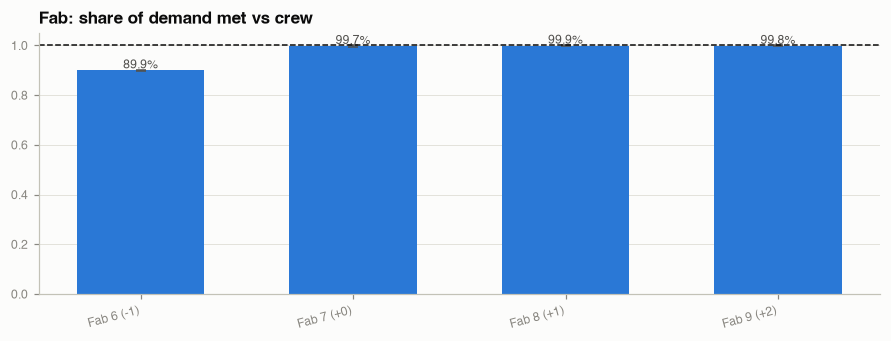

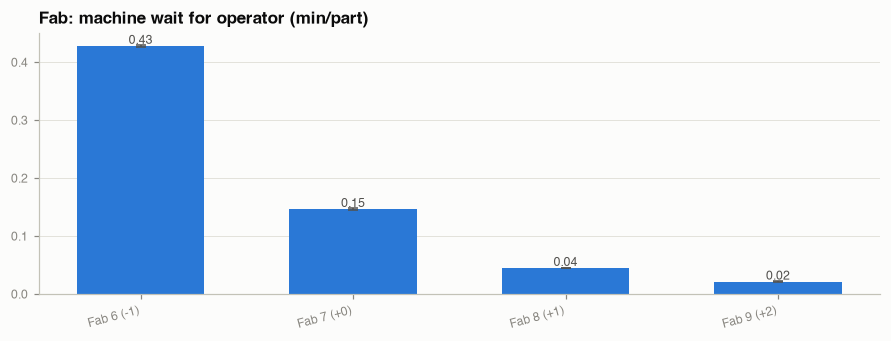

Scenario,Asm 12 (-1),Asm 13 (+0),Asm 14 (+1),Asm 15 (+2)
KPI,,,,
Throughput|Total per week,3.6e+03 ± 5.8,3.6e+03 ± 10,3.6e+03 ± 12,3.61e+03 ± 11
Throughput|% of demand,0.997 ± 0.0016,0.997 ± 0.0029,0.997 ± 0.0034,0.999 ± 0.003
WIP|Average WIP (parts),1.03e+03 ± 9.8,985 ± 6.4,979 ± 2.6,983 ± 4.3
WIP|Ending WIP (parts),793 ± 16,779 ± 5.3,767 ± 17,772 ± 18
Flow time (hr)|M860,16.2 ± 0.17,14.8 ± 0.13,14.6 ± 0.054,14.7 ± 0.077
Flow time (hr)|M970,16 ± 0.16,15.4 ± 0.11,15.4 ± 0.049,15.4 ± 0.051
Flow time (hr)|M1080,14.6 ± 0.15,13.8 ± 0.096,13.8 ± 0.043,13.8 ± 0.063
Operators|Fab utilization,0.885 ± 0.00044,0.885 ± 0.00022,0.885 ± 0.00018,0.885 ± 0.00012
Operators|Asm utilization,0.943 ± 0.0015,0.871 ± 0.0013,0.809 ± 0.0016,0.756 ± 0.0013


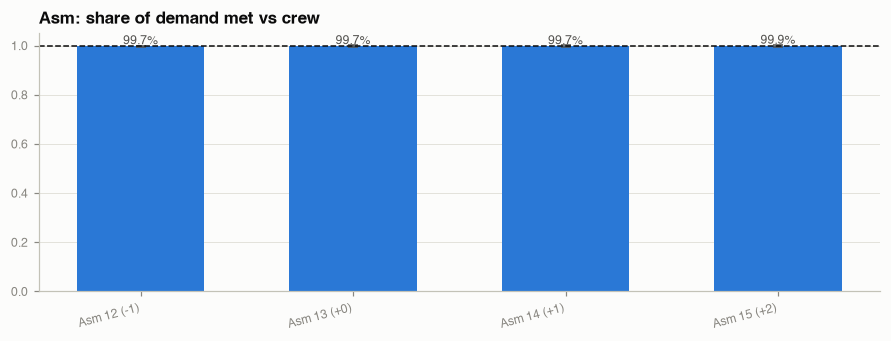

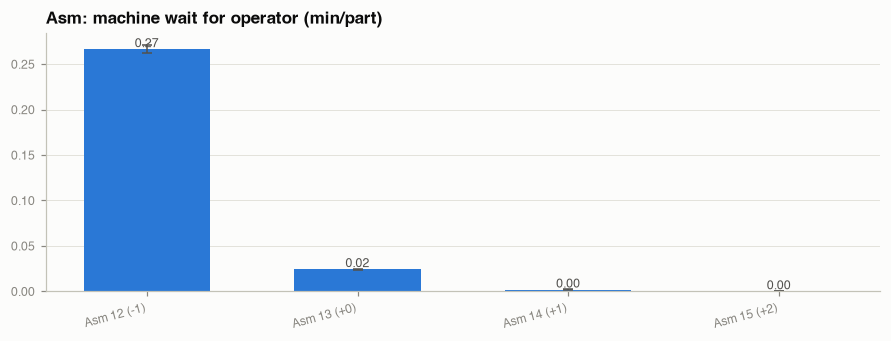

In [ ]:
for cell in ["Fab", "Asm"]:
    long_o, wide_o = X.operator_sweep(YEAR, cell=cell, deltas=(-1, 0, 1, 2), n=5, n_jobs=N_JOBS)
    display(wide_o.loc[X.KEY_KPIS])
    P.plot_compare(long_o, "Throughput|% of demand", f"{cell}: share of demand met vs crew", fmt="{:.1%}", ref=1.0)
    P.plot_compare(long_o, f"Operators|{cell} wait for operator (min/part)", f"{cell}: machine wait for operator (min/part)", fmt="{:.2f}")
    plt.show()

## 12. Capacity what-ifs
- Phase 1 recommended one more bench at 9-M and at 10-M.
- The other options test the stations the simulation flags.
- Edit `extra` to try anything else.

Scenario,Plan,+1 bench 9-M & 10-M,+1 bench 1-M,"+1 bench 1-M, +1 Fab op"
KPI,,,,
Throughput|Total per week,3.6e+03 ± 10,3.55e+03 ± 9.8,3.61e+03 ± 13,3.61e+03 ± 8
Throughput|% of demand,0.997 ± 0.0029,0.982 ± 0.0027,0.998 ± 0.0036,0.999 ± 0.0022
WIP|Average WIP (parts),985 ± 6.4,1.26e+03 ± 23,997 ± 4.7,829 ± 9.1
WIP|Ending WIP (parts),779 ± 5.3,1.25e+03 ± 66,1.02e+03 ± 15,885 ± 17
Flow time (hr)|M860,14.8 ± 0.13,19.5 ± 0.47,14.6 ± 0.08,11.8 ± 0.13
Flow time (hr)|M970,15.4 ± 0.11,21.5 ± 0.4,15.7 ± 0.077,13.9 ± 0.11
Flow time (hr)|M1080,13.8 ± 0.096,20.3 ± 0.57,13.4 ± 0.049,11.7 ± 0.07
Operators|Fab utilization,0.885 ± 0.00022,0.886 ± 0.00011,0.887 ± 7.5e-05,0.776 ± 0.00023
Operators|Asm utilization,0.871 ± 0.0013,0.869 ± 0.0012,0.871 ± 0.002,0.872 ± 0.0015


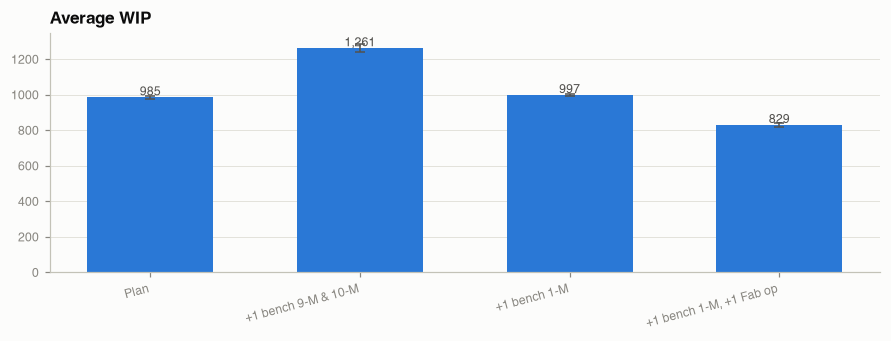

In [ ]:
from lcd_sim.params import MACHINES
m = MACHINES[YEAR]
long_c, wide_c = X.capacity_whatif(YEAR, n=5, n_jobs=N_JOBS, extra={
    "+1 bench 1-M": {"machines": {"1-M": m["1-M"] + 1}},
    "+1 bench 1-M, +1 Fab op": {"machines": {"1-M": m["1-M"] + 1}, "operators": {"Fab": sc.operators["Fab"] + 1}},
})
display(wide_c.loc[X.KEY_KPIS])
P.plot_compare(long_c, "WIP|Average WIP (parts)", "Average WIP", fmt="{:,.0f}"); plt.show()

## 13. Years 1-3 side by side (Phase 1 plan for each year)

In [ ]:
long_y, wide_y = X.years_compare(n=5, n_jobs=N_JOBS)
display(wide_y.loc[X.KEY_KPIS])
display(wide_y.loc[[k for k in wide_y.index if k.startswith("Station utilization")]])

Scenario,Year 1,Year 2,Year 3
KPI,,,
Throughput|Total per week,2.38e+03 ± 12,2.79e+03 ± 9.2,3.6e+03 ± 10
Throughput|% of demand,0.965 ± 0.0048,0.936 ± 0.0031,0.997 ± 0.0029
WIP|Average WIP (parts),1.48e+03 ± 27,4.33e+03 ± 63,985 ± 6.4
WIP|Ending WIP (parts),2.29e+03 ± 49,7.02e+03 ± 31,779 ± 5.3
Flow time (hr)|M860,27.1 ± 0.41,40.4 ± 0.56,14.8 ± 0.13
Flow time (hr)|M970,25.4 ± 0.39,37.3 ± 0.52,15.4 ± 0.11
Flow time (hr)|M1080,24.4 ± 0.38,38.1 ± 0.48,13.8 ± 0.096
Operators|Fab utilization,0.837 ± 0.00048,0.839 ± 0.00034,0.885 ± 0.00022
Operators|Asm utilization,0.831 ± 0.0035,0.794 ± 0.0016,0.871 ± 0.0013


Scenario,Year 1,Year 2,Year 3
KPI,,,
Station utilization|1-M,0.67 ± 4.3e-06,0.806 ± 2.7e-06,0.964 ± 2e-05
Station utilization|2-M,0.94 ± 0.00041,0.59 ± 1.3e-06,0.706 ± 1.5e-05
Station utilization|3-A,0.752 ± 0.00047,0.88 ± 0.00021,0.575 ± 0.00018
Station utilization|4-A,0.484 ± 0.00012,0.578 ± 1e-06,0.686 ± 9.1e-06
Station utilization|5-A,0.843 ± 0.0003,0.79 ± 0.00062,0.861 ± 0.00047
Station utilization|6-A,0.641 ± 0.00019,0.808 ± 8.2e-05,0.658 ± 4.4e-05
Station utilization|7-M,0.322 ± 0.0012,0.363 ± 0.0012,0.451 ± 0.00097
Station utilization|8-A,0.49 ± 0.0012,0.578 ± 0.0013,0.739 ± 0.00092
Station utilization|9-M,0.899 ± 0.0038,0.839 ± 0.0017,0.909 ± 0.0011


## 14. Experiment 1: whole-lot versus continuous arrivals

Both policies use the same 75% setup reduction, resources, EOQ run quantities, annual planned kit volume, lot sequence, and station lot gates. Ten replications use matching seed numbers; event order and scrap outcomes can differ between policies. Compare time-average WIP, output, and individual-kit flow time. The unit-by-unit M860/M970/M1080 rotation is a separate future experiment.

Whole-lot arrivals  Continuous arrivals  Change %
Category       Statistic                                                             
WIP            Average WIP (parts)           1,471.215              984.301   -33.096
               Ending WIP (parts)            1,211.100              772.100   -36.248
Throughput     Total per week                3,612.225            3,608.812    -0.094
               % of demand                       1.000                0.999    -0.094
Flow time (hr) M860                             19.191               14.828   -22.734
               M970                             20.212               15.406   -23.777
               M1080                            19.418               13.784   -29.017

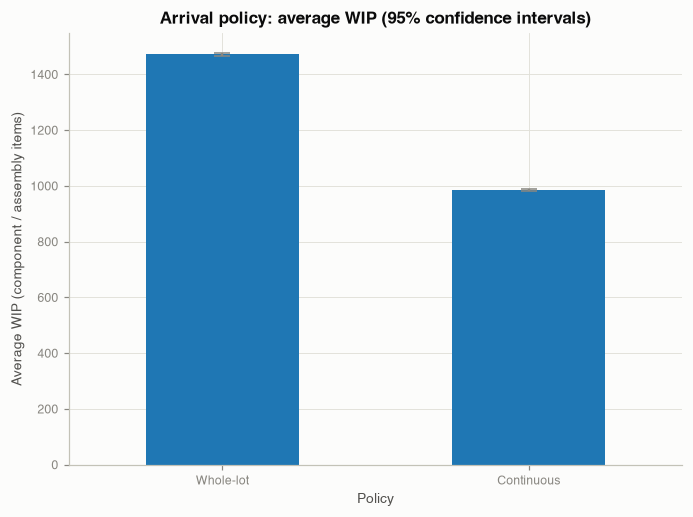

In [ ]:
from dataclasses import replace
_, batch_summary = run_replications(replace(sc, release_mode="batch"), n=10, n_jobs=N_JOBS)
comparison_keys = [
    ("WIP", "Average WIP (parts)"),
    ("WIP", "Ending WIP (parts)"),
    ("Throughput", "Total per week"),
    ("Throughput", "% of demand"),
    *[("Flow time (hr)", model) for model in ("M860", "M970", "M1080")],
]
arrival_comparison = pd.concat([
    batch_summary.loc[comparison_keys, "Average"].rename("Whole-lot arrivals"),
    summary.loc[comparison_keys, "Average"].rename("Continuous arrivals"),
], axis=1)
arrival_comparison["Change %"] = (arrival_comparison["Continuous arrivals"] / arrival_comparison["Whole-lot arrivals"] - 1) * 100
display(arrival_comparison)
wip_comparison = pd.concat([
    batch_summary.loc[[("WIP", "Average WIP (parts)")], ["Average", "Half Width"]].assign(Policy="Whole-lot"),
    summary.loc[[("WIP", "Average WIP (parts)")], ["Average", "Half Width"]].assign(Policy="Continuous"),
]).set_index("Policy")
ax = wip_comparison["Average"].plot.bar(yerr=wip_comparison["Half Width"], capsize=5, rot=0,
    ylabel="Average WIP (component / assembly items)", title="Arrival policy: average WIP (95% confidence intervals)")
plt.tight_layout(); plt.show()


## 15. Experiment 2: one-unit M860 → M970 → M1080 rotation

One kit arrives every 1.020 productive minutes in strict product order. All stations use FIFO queues across products, without lot gates; parallel machines can process different models simultaneously. An idle machine already set for the arriving unit is preferred. Setup is charged on every machine model change, using the destination model's setup input, including the first setup.

The total kit rate, resources, setup reductions, failures, and maintenance match Experiment 1. **The arrival mix is now equal thirds**, so this comparison changes sequencing, dispatch, and product mix together. Demand targets remain unchanged. EOQ identifiers are retained only for existing scrap-planning and same-product component-matching accounting; units never wait for the rest of their group to be released or processed. There is no WIP cap.

The run has a two-week warm-up and eight-week measurement window. If WIP grows through that window, the reported average is a finite-window result, not a steady-state inventory level.

One kit every 1.0197 productive min; strict M860 → M970 → M1080
Accounting checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.8874630896149193}


,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,2210.0,276.250,1277.54,0.216236,352.345452,525.758919
M970,2398.0,299.750,1105.92,0.271041,349.356513,532.585083
M1080,2359.0,294.875,1230.32,0.239673,350.509110,532.223572
Total,6967.0,870.875,3613.78,0.240987,350.694898,530.456783


,Machines,Utilization,Setup %,WaitOp %,Avg queue,Max queue,Setups,Throughput (units/hr)
Station,,,,,,,,
1-M,2,0.993488,0.734369,0.006512,19338.081033,32233.0,3172,15.861667
2-M,2,0.999084,0.828530,0.000638,762.349641,1271.0,2834,14.170000
3-A,2,0.389798,0.246915,0.031359,0.005214,6.0,8302,14.068333
4-A,1,0.834144,0.656306,0.034952,0.437646,17.0,9038,15.061667
5-A,6,0.211216,0.000018,0.011582,0.000000,1.0,1,13.880000
6-A,3,0.161144,0.001334,0.038675,0.001143,2.0,13,13.273333
7-M,1,0.095859,0.000000,0.009353,0.000000,1.0,0,4.371667
8-A,2,0.377792,0.198081,0.020370,0.018795,4.0,4734,12.976667
9-M,6,0.225313,0.000000,0.000000,0.000000,1.0,0,12.518333


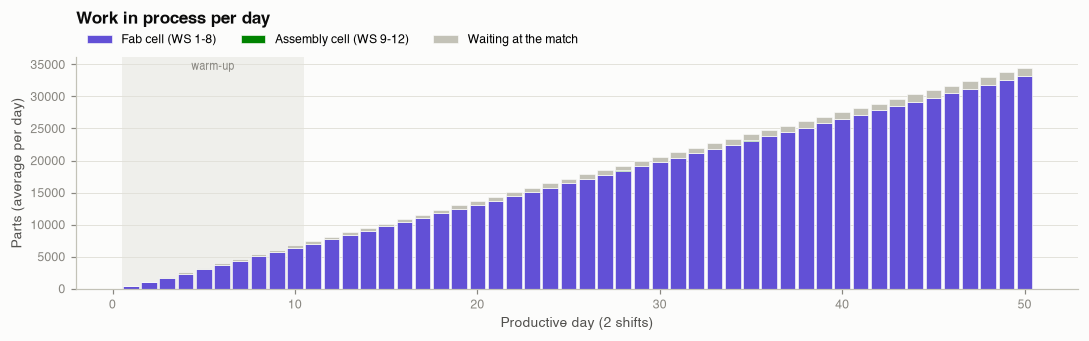

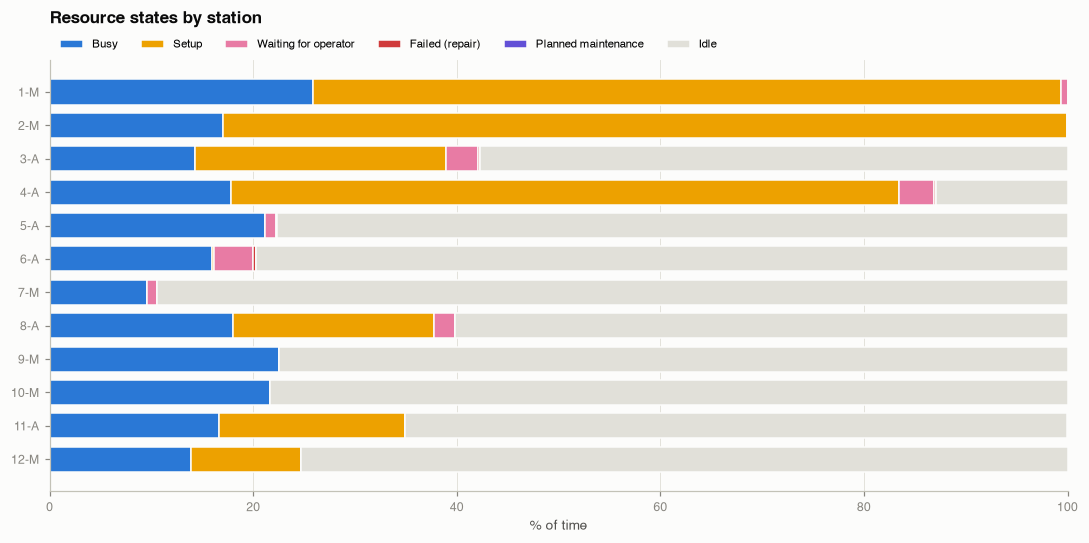

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lcd_sim.params import get_scenario, MODELS
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P

EXP2_YEAR = 3
EXP2_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))
cyclic_sc = get_scenario(EXP2_YEAR, release_mode="cyclic")
cyclic_res = run(cyclic_sc)
assert all(v == 0 for k, v in cyclic_res.checks.items() if "must be 0" in k), cyclic_res.checks
assert (cyclic_res.stations["Gate-blocked %"] == 0).all()
print(f"One kit every {cyclic_sc.kit_interarrival_min:.4f} productive min; strict M860 → M970 → M1080")
print("Accounting checks:", cyclic_res.checks)
display(cyclic_res.throughput)
display(cyclic_res.stations[["Machines", "Utilization", "Setup %", "WaitOp %", "Avg queue", "Max queue", "Setups", "Throughput (units/hr)"]])
P.plot_wip(cyclic_res); plt.show()
P.plot_machine_states(cyclic_res, by="station"); plt.show()


In [ ]:
continuous_exp2_sc = get_scenario(EXP2_YEAR, release_mode="continuous")
_, continuous_exp2_summary = run_replications(continuous_exp2_sc, n=10, n_jobs=EXP2_JOBS)
_, cyclic_summary = run_replications(cyclic_sc, n=10, n_jobs=EXP2_JOBS)
exp2_keys = [
    ("WIP", "Average WIP (parts)"), ("WIP", "Ending WIP (parts)"),
    ("Throughput", "Total per week"), ("Throughput", "% of demand"),
    *[("Throughput", f"{m} per week") for m in MODELS],
    *[("Flow time (hr)", m) for m in MODELS],
]
cyclic_comparison = pd.concat([
    continuous_exp2_summary.loc[exp2_keys, "Average"].rename("Continuous product runs"),
    cyclic_summary.loc[exp2_keys, "Average"].rename("Unit rotation / mixed stations"),
], axis=1)
cyclic_comparison["Change %"] = (cyclic_comparison.iloc[:, 1] / cyclic_comparison.iloc[:, 0] - 1) * 100
display(cyclic_comparison)
display(cyclic_summary.loc[[("WIP", "Average WIP (parts)"), ("Throughput", "Total per week")], ["Average", "Half Width"]])


Continuous product runs  \
Category       Statistic                                      
WIP            Average WIP (parts)               984.300975   
               Ending WIP (parts)                772.100000   
Throughput     Total per week                   3608.812500   
               % of demand                         0.998625   
               M860 per week                    1312.087500   
               M970 per week                    1110.262500   
               M1080 per week                   1186.462500   
Flow time (hr) M860                               14.827860   
               M970                               15.406424   
               M1080                              13.783501   

                                    Unit rotation / mixed stations  \
Category       Statistic                                             
WIP            Average WIP (parts)                    20939.207297   
               Ending WIP (parts)                     34786.000000   
Throughput     Total per week                           870.300000   
               % of demand                                0.240828   
               M860 per week                            276.375000   
               M970 per week                            300.175000   
               M1080 per week                           293.750000   
Flow time (hr) M860                                     349.611928   
               M970                                     348.599993   
               M1080                                    349.026599   

                                       Change %  
Category       Statistic                         
WIP            Average WIP (parts)  2027.317541  
               Ending WIP (parts)   4405.374951  
Throughput     Total per week        -75.884034  
               % of demand           -75.884034  
               M860 per week         -78.936237  
               M970 per week         -72.963601  
               M1080 per week        -75.241527  
Flow time (hr) M860                 2257.804381  
               M970                 2162.692494  
               M1080                2432.205681

,,Average,Half Width
Category,Statistic,,
WIP,Average WIP (parts),20939.207297,6.140012
Throughput,Total per week,870.300000,2.554575


WIP near measurement start: 7,061; near end: 34,744
Net WIP growth over measurement window: 27,683 items
WIP includes components and assemblies, not only finished-display equivalents.


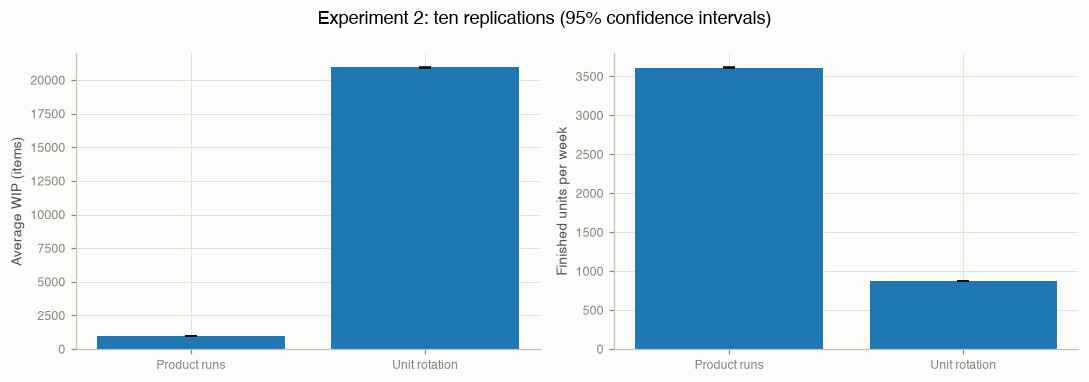

In [ ]:
trace = cyclic_res.trace
window = trace[trace.t >= cyclic_sc.warmup_min]
first = window.iloc[0]
last = window.iloc[-1]
print(f"WIP near measurement start: {first['WIP']:,.0f}; near end: {last['WIP']:,.0f}")
print(f"Net WIP growth over measurement window: {last['WIP'] - first['WIP']:,.0f} items")
print("WIP includes components and assemblies, not only finished-display equivalents.")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, key, label in zip(axes,
    [("WIP", "Average WIP (parts)"), ("Throughput", "Total per week")],
    ["Average WIP (items)", "Finished units per week"]):
    vals = [continuous_exp2_summary.loc[key, "Average"], cyclic_summary.loc[key, "Average"]]
    errors = [continuous_exp2_summary.loc[key, "Half Width"], cyclic_summary.loc[key, "Half Width"]]
    ax.bar(["Product runs", "Unit rotation"], vals, yerr=errors, capsize=4)
    ax.set_ylabel(label)
fig.suptitle("Experiment 2: ten replications (95% confidence intervals)")
fig.tight_layout(); plt.show()
